In [1]:
# Imports, seeds, device
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math as m
import time
import os

show_plots = False

np.random.seed(1234)
torch.manual_seed(1234)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(1234)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:
# MLP builder with Tanh and Xavier
def build_mlp(layers):
    modules = []
    for i in range(len(layers)-1):
        linear = nn.Linear(layers[i], layers[i+1])
        nn.init.xavier_normal_(linear.weight)
        nn.init.zeros_(linear.bias)
        modules.append(linear)
        if i < len(layers)-2:
            modules.append(nn.Tanh())
    return nn.Sequential(*modules).to(device)

In [3]:
def getGaussPoints(l_value, pts_per_section, numGauss):
    sections = [(-1.0, -2*l_value), (-2*l_value, 2*l_value), (2*l_value, 1.0)]
    elems_per_section = pts_per_section // numGauss

    if numGauss == 4:
        gaussPts = np.array([-0.861136311594053, -0.339981043584856, 0.339981043584856, 0.861136311594053])
        gaussWts = np.array([0.347854845137454, 0.652145154862546, 0.652145154862546, 0.347854845137454])
    elif numGauss == 3:
        gaussPts = np.array([-0.774596669241483, 0.0, 0.774596669241483])
        gaussWts = np.array([0.555555555555556, 0.888888888888889, 0.555555555555556])
    elif numGauss == 2:
        gaussPts = np.array([-0.577350269189626, 0.577350269189626])
        gaussWts = np.array([1.0, 1.0])
    elif numGauss == 1:
        gaussPts = np.array([0.0])
        gaussWts = np.array([2.0])
    else:
        raise ValueError("Unsupported number of Gauss points")

    all_points, all_weights, all_vertices = [], [], []
    for i, (start, end) in enumerate(sections):
        elems = np.linspace(start, end, elems_per_section+1)
        sec_vertices = elems if i == len(sections)-1 else elems[:-1]
        all_vertices.extend(sec_vertices)

        section_pts = np.zeros((elems_per_section * numGauss, 1))
        section_wts = np.zeros((elems_per_section * numGauss, 1))
        for iElem in range(elems_per_section):
            x1, x2 = elems[iElem], elems[iElem+1]
            elemLen = x2 - x1
            for iGauss in range(numGauss):
                section_pts[iElem*numGauss + iGauss, 0] = 0.5 * ((x2 - x1) * gaussPts[iGauss] + x2 + x1)
                section_wts[iElem*numGauss + iGauss, 0] = gaussWts[iGauss] * 0.5 * elemLen

        all_points.append(section_pts)
        all_weights.append(section_wts)

    xPhys = np.vstack(all_points)
    wgtsPhys = np.vstack(all_weights)
    vertex = np.array(all_vertices)
    return xPhys, wgtsPhys, vertex

def getElmtIntPts(vertex, numGauss=4):
    numElemU = len(vertex) - 1
    if numGauss == 1:
        gaussPts = np.array([0.0]); gaussWts = np.array([2.0])
    elif numGauss == 2:
        gaussPts = np.array([-0.577350269189626, 0.577350269189626]); gaussWts = np.array([1.0, 1.0])
    elif numGauss == 3:
        gaussPts = np.array([-0.774596669241483, 0.0, 0.774596669241483]); gaussWts = np.array([0.555555555555556, 0.888888888888889, 0.555555555555556])
    elif numGauss == 4:
        gaussPts = np.array([-0.861136311594053, -0.339981043584856, 0.339981043584856, 0.861136311594053]); gaussWts = np.array([0.347854845137454, 0.652145154862546, 0.652145154862546, 0.347854845137454])
    else:
        raise ValueError("Unsupported number of Gauss points")

    xPhys = np.zeros((numElemU * numGauss, 1))
    wgtsPhys = np.zeros((numElemU * numGauss, 1))
    for iElem in range(numElemU):
        x1, x2 = vertex[iElem], vertex[iElem+1]
        elemLen = x2 - x1
        for iGauss in range(numGauss):
            xPhys[iElem*numGauss + iGauss, 0] = 0.5 * ((x2 - x1) * gaussPts[iGauss] + x2 + x1)
            wgtsPhys[iElem*numGauss + iGauss, 0] = gaussWts[iGauss] * 0.5 * elemLen
    return xPhys, wgtsPhys

def refineElemVertex(vertex, index_ref):
    vertex_ref = vertex.copy()
    index_ref = np.sort(index_ref)[::-1]
    for idx in index_ref:
        mid = 0.5 * (vertex_ref[idx] + vertex_ref[idx+1])
        vertex_ref = np.insert(vertex_ref, idx+1, mid)
    return vertex_ref

def scatterPlot(X_f, figHeight=4, figWidth=10, filename="points"):
    global show_plots
    fig = plt.figure(figsize=(figWidth, figHeight))
    plt.scatter(X_f[:, 0], np.zeros_like(X_f[:, 0]), c='r', marker='o', s=1)
    plt.xlim([-1.0, 1.0]); plt.ylim([-0.1, 0.1])
    plt.title("Integration Points"); plt.xlabel("x"); plt.grid(True, alpha=0.3)
    plt.savefig(filename + '.png', bbox_inches='tight', dpi=300)
    if show_plots: plt.show()
    else: plt.close(fig)

def plotResults(xSpace, u_pred, phi_pred, u_exact, phi_exact, figHeight=4, figWidth=12):
    global show_plots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(figWidth, figHeight))
    ax1.plot(xSpace, u_exact, 'b-', label='Exact'); ax1.plot(xSpace, u_pred, 'r--', label='Predicted')
    ax1.set_xlabel('x'); ax1.set_ylabel('Displacement (u)'); ax1.set_title('Displacement Field'); ax1.legend(); ax1.grid(True, alpha=0.3)
    ax2.plot(xSpace, phi_exact, 'b-', label='Exact'); ax2.plot(xSpace, phi_pred, 'r--', label='Predicted')
    ax2.set_xlabel('x'); ax2.set_ylabel('Phase Field (φ)'); ax2.set_title('Phase Field'); ax2.legend(); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.savefig('results_comparison.png', bbox_inches='tight', dpi=300)
    if show_plots: plt.show()
    else: plt.close(fig)
    error_u = np.linalg.norm(u_exact-u_pred, 2)/np.linalg.norm(u_exact, 2)
    error_phi = np.linalg.norm(phi_exact-phi_pred, 2)/np.linalg.norm(phi_exact, 2)
    print(f'Relative error u: {error_u:.6e}')
    print(f'Relative error phi: {error_phi:.6e}')

def plotConvergence(adam_buff, lbfgs_buff=None, figHeight=4, figWidth=10):
    global show_plots
    fig = plt.figure(figsize=(figWidth, figHeight))
    plt.semilogy(range(len(adam_buff)), adam_buff, 'b-', label='Adam Loss')
    if lbfgs_buff is not None and len(lbfgs_buff) > 0:
        plt.semilogy(range(len(adam_buff), len(adam_buff) + len(lbfgs_buff)), lbfgs_buff, 'r-', label='L-BFGS Loss')
    plt.xlabel('Iterations'); plt.ylabel('Loss (log scale)'); plt.title('Training Convergence'); plt.legend(); plt.grid(True, alpha=0.3)
    plt.savefig('convergence.png', bbox_inches='tight', dpi=300)
    if show_plots: plt.show()
    else: plt.close(fig)

def plot_final_loss(adam_losses, lbfgs_losses, figsize=(10, 6)):
    plt.figure(figsize=figsize)
    adam_iters = range(len(adam_losses))
    plt.semilogy(adam_iters, adam_losses, 'b-', linewidth=2, label='Adam')
    if lbfgs_losses and len(lbfgs_losses) > 0:
        lbfgs_iters = range(len(adam_losses), len(adam_losses) + len(lbfgs_losses))
        plt.semilogy(lbfgs_iters, lbfgs_losses, 'r-', linewidth=2, label='L-BFGS')
    plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.grid(True, which='both', linestyle='--', alpha=0.6); plt.legend(fontsize=12)
    plt.tight_layout(); plt.savefig('loss_convergence.png', dpi=300, bbox_inches='tight'); plt.show()


In [4]:
# Parameters
l = 0.0125
Gc = 2.7
E = 1.0
B = 1000.0
crackLoc = 0.0

lb = np.array([-1.0])
ub = np.array([1.0])
layers = [1, 50, 50, 50, 2]

# Integration points
pts_per_section = 112
numGauss = 4
xPhys, wgtsPhys, vertex = getGaussPoints(l, pts_per_section, numGauss)
X_f = np.concatenate((xPhys, wgtsPhys), axis=1)
X_f_tensor = torch.tensor(X_f, dtype=torch.float32, device=device)

# Evaluation grid
xLeft = np.transpose(np.array([np.linspace(-1.0, -0.025, 100)]))
xCenter = np.transpose(np.array([np.linspace(-0.025, 0.025, 400)]))
xRight = np.transpose(np.array([np.linspace(0.025, 1.0, 100)]))
xSpace = np.concatenate((xLeft, xCenter, xRight), axis=0)
xSpace_tensor = torch.tensor(xSpace, dtype=torch.float32, device=device)

# Exact fields for comparison
u_exact = np.sin(np.pi*xSpace)/(np.pi)**2 + np.where(xSpace < 0.0, -1.0*(1+xSpace)/np.pi, (1-xSpace)/np.pi)
phi_exact = np.exp(-np.absolute(xSpace)/l)*(1+np.absolute(xSpace)/l)

scatterPlot(X_f)


In [5]:
# Build model
model = build_mlp(layers)

# State dict for constants and scaling
const = {
    'l': torch.tensor([l], dtype=torch.float32, device=device),
    'Gc': torch.tensor([Gc], dtype=torch.float32, device=device),
    'E': torch.tensor([E], dtype=torch.float32, device=device),
    'B': torch.tensor([B], dtype=torch.float32, device=device),
    'lb': torch.tensor(lb, dtype=torch.float32, device=device),
    'ub': torch.tensor(ub, dtype=torch.float32, device=device),
    'crackLoc': torch.tensor([crackLoc], dtype=torch.float32, device=device),
}

def scale_to_ref(X):
    return 2.0 * (X - const['lb']) / (const['ub'] - const['lb']) - 1.0

def net_raw(x):
    return model(scale_to_ref(x))

def net_u(x):
    X = x[:, 0:1]
    uphi = net_raw(X)
    uNN = uphi[:, 0:1]
    return (X+1.0)*(X-1.0)*uNN

def net_phi(x):
    X = x[:, 0:1]
    uphi = net_raw(X)
    return uphi[:, 1:2]

def net_hist(x):
    dist = torch.abs(x - const['crackLoc'])
    condition = dist < 0.5*const['l']
    values = const['B']*const['Gc']*0.5*(1-(2*dist/const['l']))/const['l']
    return torch.where(condition, values, torch.zeros_like(dist))

def net_energy(x):
    x = x.clone().detach().requires_grad_(True)
    u = net_u(x)
    phi = net_phi(x)
    hist = net_hist(x)
    g = (1.0 - phi)**2

    phi_x = torch.autograd.grad(phi, x, grad_outputs=torch.ones_like(phi), create_graph=True)[0]
    nabla = phi_x**2
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    sigmaX = const['E'] * u_x

    energy_u = 0.5 * g * sigmaX * u_x
    ext_work = torch.sin(m.pi * x) * u
    energy_phi = 0.5 * const['Gc'] * (phi**2/const['l'] + const['l']*nabla) + g * hist
    return energy_u, energy_phi, ext_work

def net_f(x):
    x = x.clone().detach().requires_grad_(True)
    u = net_u(x)
    phi = net_phi(x)
    g = (1.0 - phi)**2
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    f_u = -g * const['E'] * u_xx
    return f_u

def loss_fn(x_f, wt_f):
    energy_u, energy_phi, ext_work = net_energy(x_f)
    loss_energy_u = torch.sum(energy_u * wt_f) - torch.sum(ext_work * wt_f)
    loss_energy_phi = torch.sum(energy_phi * wt_f)
    return loss_energy_u + loss_energy_phi


In [6]:
# Optimizers
optimizer_Adam = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer_Adam, step_size=100, gamma=0.9)

# L-BFGS configured as in original
optimizer_LBFGS = optim.LBFGS(
    model.parameters(),
    max_iter=100,
    max_eval=100,
    history_size=50,
    tolerance_grad=1e-5,
    tolerance_change=1.0 * np.finfo(float).eps,
    line_search_fn="strong_wolfe"
)

adam_losses = []
lbfgs_losses = []

def train_adam(X_f_tensor, num_iterations):
    x_f = X_f_tensor[:, 0:1]
    wt_f = X_f_tensor[:, 1:2]
    start_time = time.time()
    model.train()
    for it in range(num_iterations):
        optimizer_Adam.zero_grad()
        loss = loss_fn(x_f, wt_f)
        loss.backward()
        optimizer_Adam.step()
        scheduler.step()
        adam_losses.append(loss.item())
        if it % 1000 == 0:
            elapsed = time.time() - start_time
            print(f'It: {it}, Loss: {loss.item():.3e}, Time: {elapsed:.2f}s')
            start_time = time.time()

def train_lbfgs(X_f_tensor):
    x_f = X_f_tensor[:, 0:1]
    wt_f = X_f_tensor[:, 1:2]
    print("Starting L-BFGS optimization...")
    def closure():
        optimizer_LBFGS.zero_grad()
        loss = loss_fn(x_f, wt_f)
        loss.backward()
        lbfgs_losses.append(loss.item())
        if len(lbfgs_losses) % 5 == 0:
            print(f'LBFGS It: {len(lbfgs_losses)}, Loss: {loss.item():.3e}')
        return loss
    optimizer_LBFGS.step(closure)


In [7]:
@torch.no_grad()
def predict_u_phi(X_star):
    x = X_star[:, 0:1]
    u = net_u(x)
    phi = net_phi(x)
    return u, phi

def predict_f(X_star):
    x = X_star[:, 0:1]
    return net_f(x)

In [8]:
numSteps = 4
num_train_its = 2000

for step in range(numSteps):
    print(f"\n=== Refinement Step {step+1}/{numSteps} ===")
    print(f"Number of integration points: {X_f.shape[0]}")

    # Adam then L-BFGS
    train_adam(X_f_tensor, num_train_its)
    train_lbfgs(X_f_tensor)

    # Convergence plot
    plotConvergence(adam_losses, lbfgs_losses)

    # Predictions and plots
    u_pred, phi_pred = predict_u_phi(xSpace_tensor)
    u_pred = u_pred.cpu().numpy()
    phi_pred = phi_pred.cpu().numpy()
    plotResults(xSpace, u_pred, phi_pred, u_exact, phi_exact)

    if step == numSteps - 1:
        break

    # Residual-based error
    f_u = predict_f(X_f_tensor).detach().cpu().numpy()
    res_err = np.sqrt(f_u**2)

    # Element-wise error aggregation
    numElem = len(vertex) - 1
    errElem = np.zeros(numElem)
    for iElem in range(numElem):
        ptIndStart = iElem*numGauss
        ptIndEnd = (iElem+1)*numGauss
        errElem[iElem] = np.sum(res_err[ptIndStart:ptIndEnd] * X_f[ptIndStart:ptIndEnd, 1])

    # Mark top N% for refinement
    N = 10
    ntop = int(np.round(numElem*N/100))
    sort_err_ind = np.argsort(-errElem, axis=0)
    index_ref = np.squeeze(sort_err_ind[0:ntop])

    # Refine and rebuild quadrature
    vertex = refineElemVertex(vertex, index_ref)
    xPhys, wgtsPhys = getElmtIntPts(vertex, numGauss)
    X_f = np.concatenate((xPhys, wgtsPhys), axis=1)
    X_f_tensor = torch.tensor(X_f, dtype=torch.float32, device=device)

    scatterPlot(X_f, filename=f"refined_points_{step+1}")

print("\n=== Training Complete ===")



=== Refinement Step 1/4 ===
Number of integration points: 336
It: 0, Loss: 6.761e+02, Time: 0.12s
It: 1000, Loss: 6.047e+00, Time: 10.90s
Starting L-BFGS optimization...
LBFGS It: 5, Loss: 4.714e+00
LBFGS It: 10, Loss: 4.703e+00
LBFGS It: 15, Loss: 4.445e+00
LBFGS It: 20, Loss: 4.307e+00
LBFGS It: 25, Loss: 4.296e+00
LBFGS It: 30, Loss: 4.226e+00
LBFGS It: 35, Loss: 4.181e+00
LBFGS It: 40, Loss: 4.131e+00
LBFGS It: 45, Loss: 4.094e+00
LBFGS It: 50, Loss: 4.061e+00
LBFGS It: 55, Loss: 4.052e+00
LBFGS It: 60, Loss: 4.099e+00
LBFGS It: 65, Loss: 4.035e+00
LBFGS It: 70, Loss: 4.020e+00
LBFGS It: 75, Loss: 4.018e+00
LBFGS It: 80, Loss: 4.016e+00
LBFGS It: 85, Loss: 4.009e+00
LBFGS It: 90, Loss: 4.008e+00
LBFGS It: 95, Loss: 4.006e+00
LBFGS It: 100, Loss: 4.006e+00
Relative error u: 7.097397e-01
Relative error phi: 1.461734e-01

=== Refinement Step 2/4 ===
Number of integration points: 368
It: 0, Loss: 4.006e+00, Time: 0.02s
It: 1000, Loss: 4.001e+00, Time: 11.70s
Starting L-BFGS optimizati

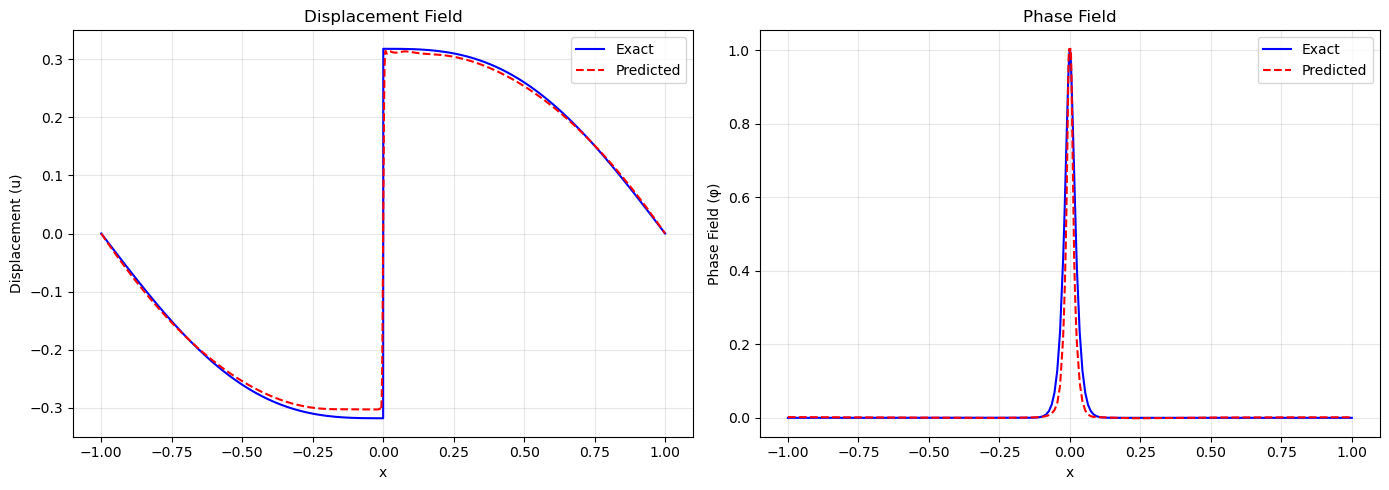

Relative error u: 2.173174e-01
Relative error phi: 2.208326e-01


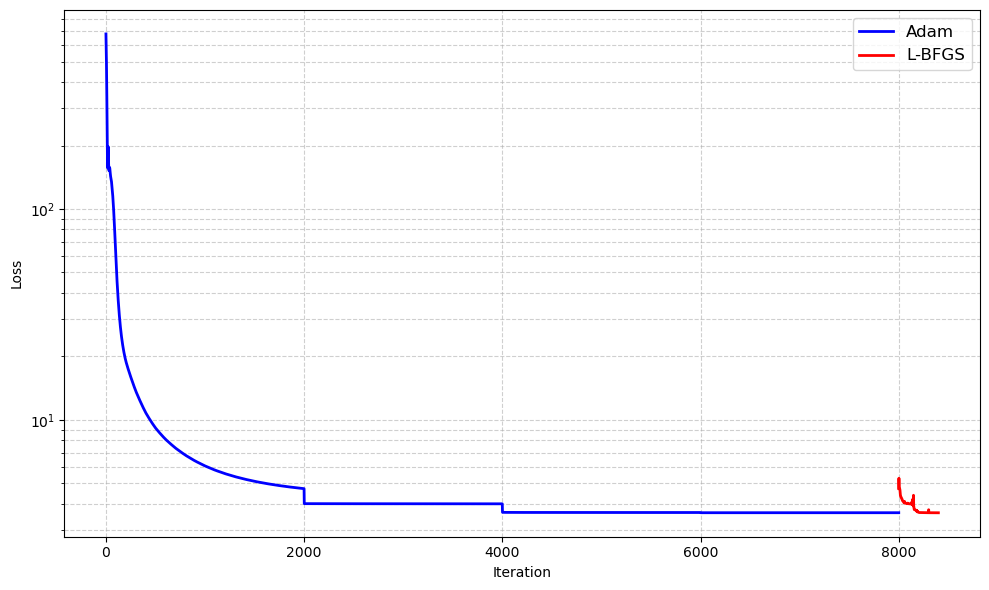

Model weights saved to pinn_model.pth


In [9]:
show_plots = True

u_pred, phi_pred = predict_u_phi(xSpace_tensor)
u_pred = u_pred.cpu().numpy()
phi_pred = phi_pred.cpu().numpy()

plotResults(xSpace, u_pred, phi_pred, u_exact, phi_exact, figHeight=5, figWidth=14)
plot_final_loss(adam_losses, lbfgs_losses)

try:
    torch.save(model.state_dict(), "pinn_model.pth")
    print("Model weights saved to pinn_model.pth")
except Exception as e:
    print(f"Could not save model weights: {e}")
